# Programação Quântica na Prática — Gabarito Completo
**Palestrante:** Yohanna Dvorak (`ydvorak@id.uff.br`)

Notebook completo com todos os exercícios resolvidos (Grover $n=2$, Grover + Somador de Cuccaro $n=2$ e demonstração extra do Grover + Somador de Cuccaro para $n=3$), circuitos desenhados com `output='mpl'` no estilo verde e vinho dos slides e histogramas com todos os estados.

In [10]:
# Se estiver rodando no Google Colab, esta célula instala os pacotes automaticamente:
try:
    import qiskit, qiskit_aer, pylatexenc
except ImportError:
    !pip install -q qiskit qiskit-aer pylatexenc matplotlib
print("Pacotes prontos!")


Pacotes prontos!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.circuit.library import UnitaryGate, CDKMRippleCarryAdder

simulador = AerSimulator()

# Paleta de cores dos slides
COR_VERDE   = "#385E46"  # Verde musgo principal
COR_SALVIA  = "#528062"  # Verde sálvia secundário
COR_VINHO   = "#76232F"  # Bordô / vinho de destaque
COR_CREME   = "#F6F5F0"  # Fundo creme suave
COR_CARVAO  = "#232B26"  # Texto e bordas

# Estilo visual do circuito em Matplotlib (verde e vinho igual aos slides)
ESTILO_CIRCUITO_SLIDE = {
    "backgroundcolor": COR_CREME,
    "linecolor": COR_CARVAO,
    "textcolor": COR_CARVAO,
    "gatefacecolor": COR_VERDE,
    "gatetextcolor": COR_CREME,
    "barrierfacecolor": COR_SALVIA,
    "creglinecolor": COR_VERDE,
    "displaycolor": {
        "h": (COR_VERDE, COR_CREME),
        "x": (COR_VINHO, COR_CREME),
        "y": (COR_VINHO, COR_CREME),
        "z": (COR_VINHO, COR_CREME),
        "cx": (COR_VINHO, COR_CREME),
        "cz": (COR_VINHO, COR_CREME),
        "ccx": (COR_VINHO, COR_CREME),
        "s": (COR_SALVIA, COR_CREME),
        "t": (COR_SALVIA, COR_CREME),
        "ry": (COR_SALVIA, COR_CREME),
        "measure": (COR_CARVAO, COR_CREME),
    },
}

def simular(qc, shots=1024):
    """Transpila e executa o circuito no simulador Aer."""
    qc_t = transpile(qc, simulador)
    return simulador.run(qc_t, shots=shots).result().get_counts()

def plotar_histograma(counts, titulo="Resultado da Medição", estados_destaque=None, todos_estados_n_qubits=None):
    """Plota o histograma exibindo todos os estados possíveis de n bits nas cores dos slides."""
    if todos_estados_n_qubits is None and len(counts) > 0:
        todos_estados_n_qubits = len(next(iter(counts.keys())))

    if todos_estados_n_qubits is not None:
        todos = [format(i, f"0{todos_estados_n_qubits}b") for i in range(2 ** todos_estados_n_qubits)]
        dados = {estado: counts.get(estado, 0) for estado in todos}
    else:
        dados = dict(sorted(counts.items()))

    estados = list(dados.keys())
    valores = list(dados.values())
    total = max(sum(valores), 1)
    maior = max(valores) if valores else 1

    if estados_destaque is None:
        estados_destaque = [e for e, v in dados.items() if v == maior and maior > 0]

    cores = [COR_VINHO if e in estados_destaque else COR_VERDE for e in estados]

    largura_fig = max(6.8, len(estados) * 0.85)
    fig, ax = plt.subplots(figsize=(largura_fig, 3.9), facecolor=COR_CREME)
    ax.set_facecolor(COR_CREME)
    barras = ax.bar(estados, valores, color=cores, edgecolor=COR_CARVAO, linewidth=1.2, width=0.55)

    for b, v in zip(barras, valores):
        pct = 100.0 * v / total
        ax.text(b.get_x() + b.get_width() / 2, v + maior * 0.03, f"{v}\n({pct:.1f}%)",
                ha="center", va="bottom", fontweight="bold", color=COR_CARVAO, fontsize=9)

    ax.set_title(titulo, fontweight="bold", color=COR_VERDE, fontsize=12, pad=12)
    ax.set_xlabel("Estados medidos (Little-Endian: |q_{n-1}...q_0⟩)", color=COR_CARVAO)
    ax.set_ylabel("Contagens (shots)", color=COR_CARVAO)
    ax.set_ylim(0, maior * 1.28)
    ax.grid(axis="y", linestyle="--", alpha=0.35, color=COR_SALVIA)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()


---
## Exercício 0 (Gabarito): Aquecimento — Porta Customizada ($\sqrt{X}$) e Par de Bell ($\ket{\Phi^+}$)

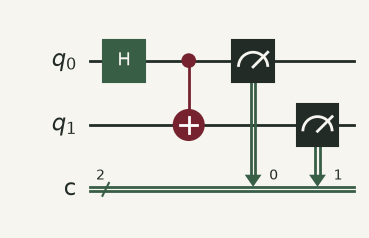

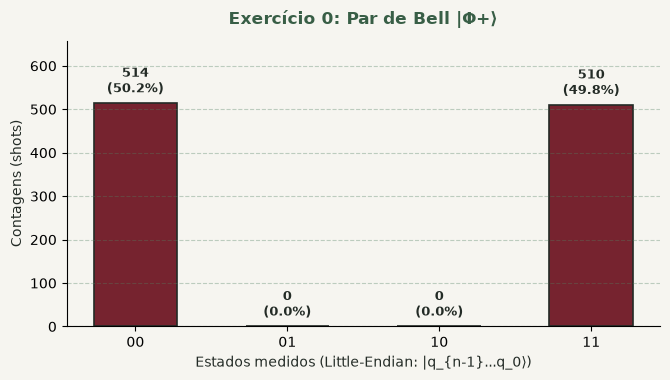

In [12]:
# 1. Criando uma porta unitária nova U (Raiz de NOT: √X)
M = 0.5 * np.array([[1 + 1j, 1 - 1j], [1 - 1j, 1 + 1j]])
porta_sx = UnitaryGate(M, label="√X")

# 2. Par Emaranhado de Bell |Φ+⟩ = (|00⟩ + |11⟩)/√2
qc_bell = QuantumCircuit(2, 2)
qc_bell.h(0)
qc_bell.cx(0, 1)
qc_bell.measure([0, 1], [0, 1])

display(qc_bell.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_bell), "Exercício 0: Par de Bell |Φ+⟩", estados_destaque=["00", "11"])

---
## Exercício 1 (Gabarito): Codificação Superdensa (*Superdense Coding*)

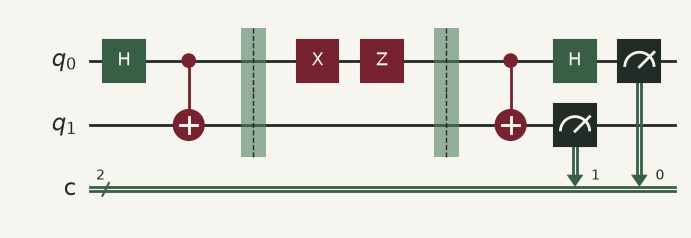

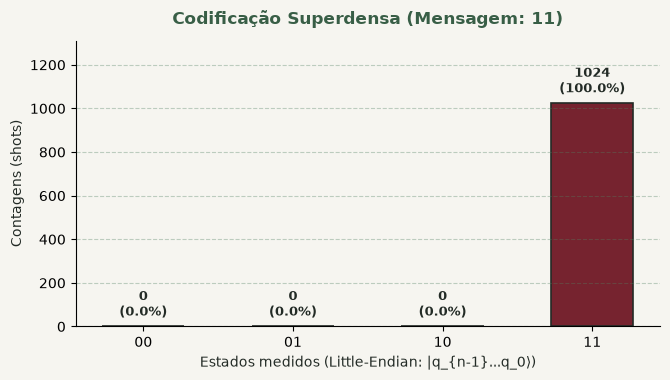

In [13]:
mensagem = "11"  # Pode testar com "00", "01", "10" ou "11"
qc_sd = QuantumCircuit(2, 2)

# 1. Par de Bell entre Alice (q0) e Bob (q1)
qc_sd.h(0)
qc_sd.cx(0, 1)
qc_sd.barrier()

# 2. Alice codifica 2 bits aplicando portas apenas em q0
if mensagem == "01":
    qc_sd.z(0)
elif mensagem == "10":
    qc_sd.x(0)
elif mensagem == "11":
    qc_sd.x(0)
    qc_sd.z(0)
qc_sd.barrier()

# 3. Bob decodifica e mede
qc_sd.cx(0, 1)
qc_sd.h(0)
qc_sd.measure([0, 1], [0, 1])

display(qc_sd.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_sd), f"Codificação Superdensa (Mensagem: {mensagem})", estados_destaque=[mensagem])

---
## Exercício 2 (Gabarito): Teletransporte Quântico (*Quantum Teleportation*)

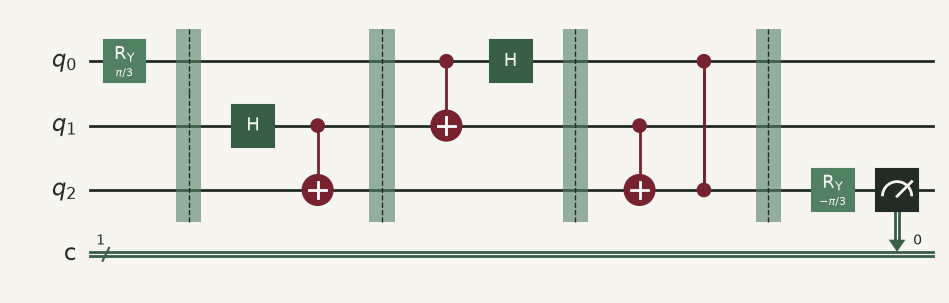

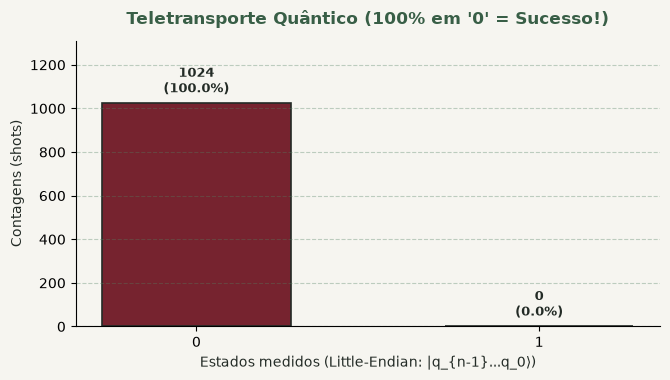

In [14]:
qc_tel = QuantumCircuit(3, 1)

# 1. Estado inicial secreto |ψ⟩ em q0 (Alice)
qc_tel.ry(np.pi / 3, 0)
qc_tel.barrier()

# 2. Par de Bell entre q1 (Alice) e q2 (Bob)
qc_tel.h(1)
qc_tel.cx(1, 2)
qc_tel.barrier()

# 3. Alice emaranha q0 com q1
qc_tel.cx(0, 1)
qc_tel.h(0)
qc_tel.barrier()

# 4. Bob aplica as correções em q2
qc_tel.cx(1, 2)
qc_tel.cz(0, 2)
qc_tel.barrier()

# 5. Verificação inversa: Ry(-pi/3) volta para |0⟩ com 100% de certeza!
qc_tel.ry(-np.pi / 3, 2)
qc_tel.measure(2, 0)

display(qc_tel.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_tel), "Teletransporte Quântico (100% em '0' = Sucesso!)", estados_destaque=["0"])

---
## Exercício 3 (Gabarito): Algoritmo de Busca de Grover ($n = 2$ Qubits)
Encontrando o estado secreto $\ket{\omega} = \ket{11}$ dentre $N = 4$ estados em **1 única iteração** (100% de sucesso):

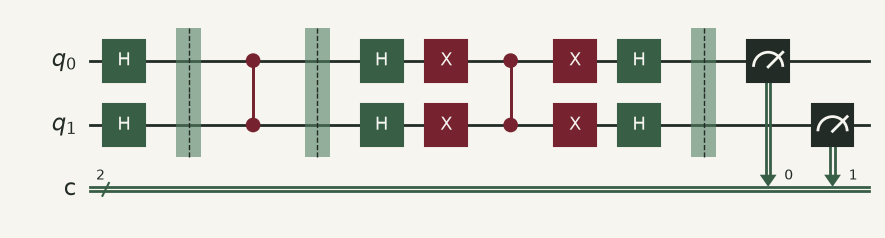

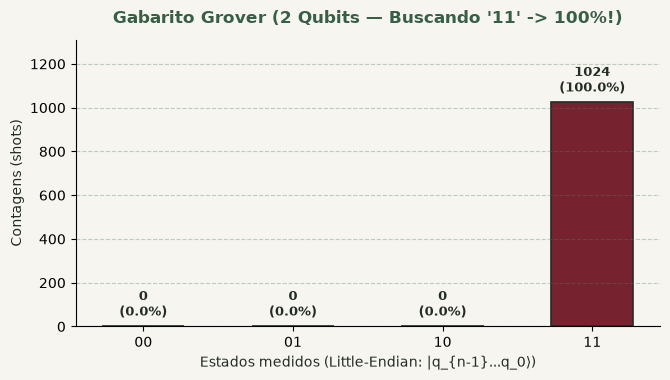

In [15]:
qc_grover = QuantumCircuit(2, 2)

# ETAPA 1: Superposição uniforme em todos os qubits
qc_grover.h([0, 1])
qc_grover.barrier()

# ETAPA 2: Oráculo que marca o estado |11⟩ com fase negativa (-|11⟩)
qc_grover.cz(0, 1)
qc_grover.barrier()

# ETAPA 3: Difusor de Grover (Inversão em torno da média)
qc_grover.h([0, 1])
qc_grover.x([0, 1])
qc_grover.cz(0, 1)
qc_grover.x([0, 1])
qc_grover.h([0, 1])
qc_grover.barrier()

# Medição final
qc_grover.measure([0, 1], [0, 1])
display(qc_grover.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))

counts_grover = simular(qc_grover)
plotar_histograma(counts_grover, "Gabarito Grover (2 Qubits — Buscando '11' -> 100%!)", estados_destaque=["11"])

---
## Exercício 4 (Gabarito): Grover com Somador de Cuccaro ($n = 2$ Bits — $A + Y = X$)
Usando o **Somador de Cuccaro (`CDKMRippleCarryAdder(2, kind="fixed")`)** para descobrir qual número **$A \in \{0, 1, 2, 3\}$** somado com **$Y = 1$ (`'01'`)** resulta em **$X = 3$ (`'11'`)**:
1. **Soma (`somador`):** Calcula $\ket{A}\ket{Y} \to \ket{A}\ket{A + Y}$ em superposição.
2. **Marca $X = 3$ (`'11'`):** Aplica `qc.cz(2, 3)` nos qubits da soma (`q2, q3`).
3. **Descomputa (`somador.inverse()`):** Desfaz a soma para desemaranhar $B$ de $A$.
4. **Difusor de Grover em $A$ (`q0, q1`):** Amplifica $A = 2$ (`'10'`, pois $2 + 1 = 3$) para **100%**!

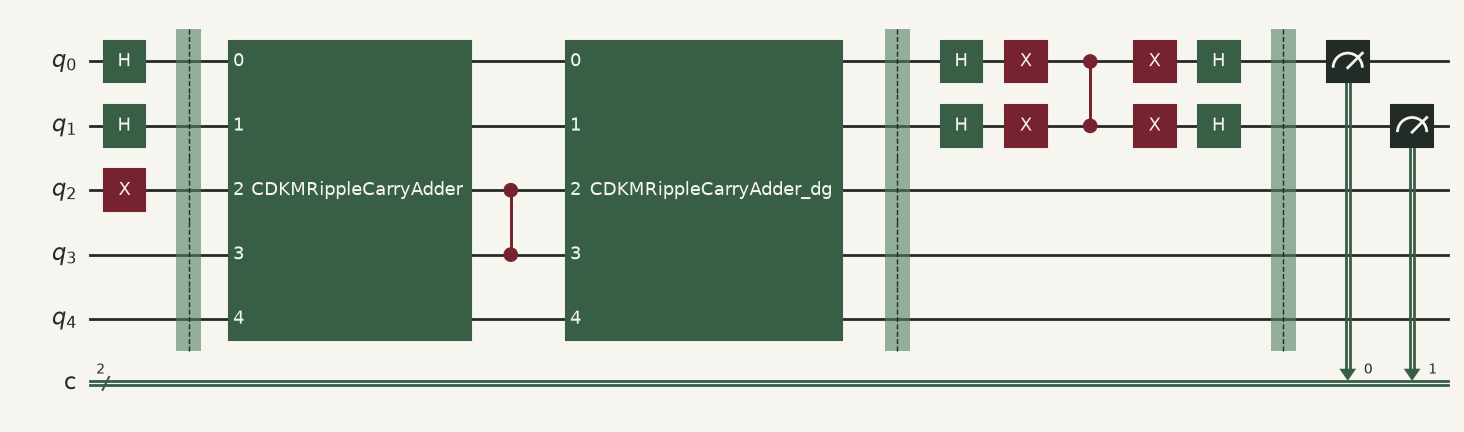

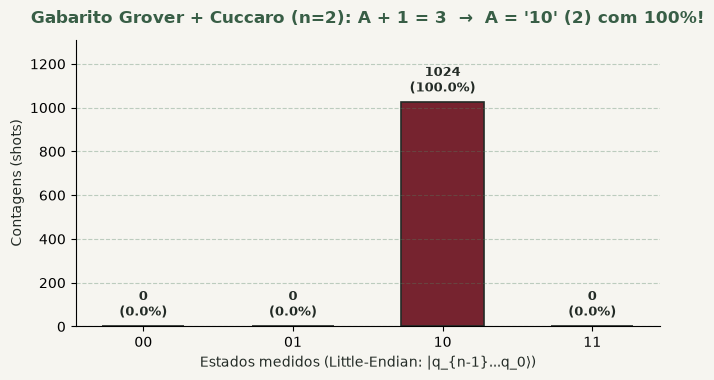

In [16]:
somador = CDKMRippleCarryAdder(2, kind="fixed")
qc_cuccaro = QuantumCircuit(5, 2)  # q0,q1 = A | q2,q3 = Y | q4 = aux

# 1. Inicializa Y = 1 ('01' -> porta X em q2) e coloca A (q0, q1) em superposição
qc_cuccaro.x(2)
qc_cuccaro.h([0, 1])
qc_cuccaro.barrier()

# 2. ORÁCULO COM SOMADOR DE CUCCARO (Soma -> Marca X=3 -> Descomputa)
qc_cuccaro.append(somador, [0, 1, 2, 3, 4])
qc_cuccaro.cz(2, 3)  # Marca X = 3 ('11') no registrador da soma (q2, q3)
qc_cuccaro.append(somador.inverse(), [0, 1, 2, 3, 4])
qc_cuccaro.barrier()

# 3. DIFUSOR DE GROVER EM A (qubits 0 e 1)
qc_cuccaro.h([0, 1])
qc_cuccaro.x([0, 1])
qc_cuccaro.cz(0, 1)
qc_cuccaro.x([0, 1])
qc_cuccaro.h([0, 1])
qc_cuccaro.barrier()

# 4. Mede o registrador A (qubits 0 e 1)
qc_cuccaro.measure([0, 1], [0, 1])

display(qc_cuccaro.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_cuccaro), "Gabarito Grover + Cuccaro (n=2): A + 1 = 3  →  A = '10' (2) com 100%!", estados_destaque=["10"])

---
## Extra (Demonstração): Grover com Somador de Cuccaro para $n = 3$ Bits ($A + Y = X$)
Demonstração com $n = 3$ bits usando `CDKMRippleCarryAdder(3, kind="fixed")` ($2n + 1 = 7$ qubits):
* Queremos descobrir qual número **$A \in \{0, \dots, 7\}$** somado com **$Y = 2$ (`'010'`)** resulta em **$X = 5$ (`'101'`)**:
$$A + 2 = 5 \implies A = 3 \text{ (\texttt{'011'} em binário)}$$
* **Qubits `0, 1, 2`:** Registrador **$A$** (incógnita de 3 bits em superposição)
* **Qubits `3, 4, 5`:** Registrador **$B$** (inicializado com $Y = 2$ `'010'` $\to$ porta $X$ em `q4`)
* **Qubit `6`:** Qubit auxiliar (`help` em $\ket{0}$)
* Em **2 iterações** de Grover, o estado $A = 3$ (`'011'`) é amplificado para **~94.5%**!

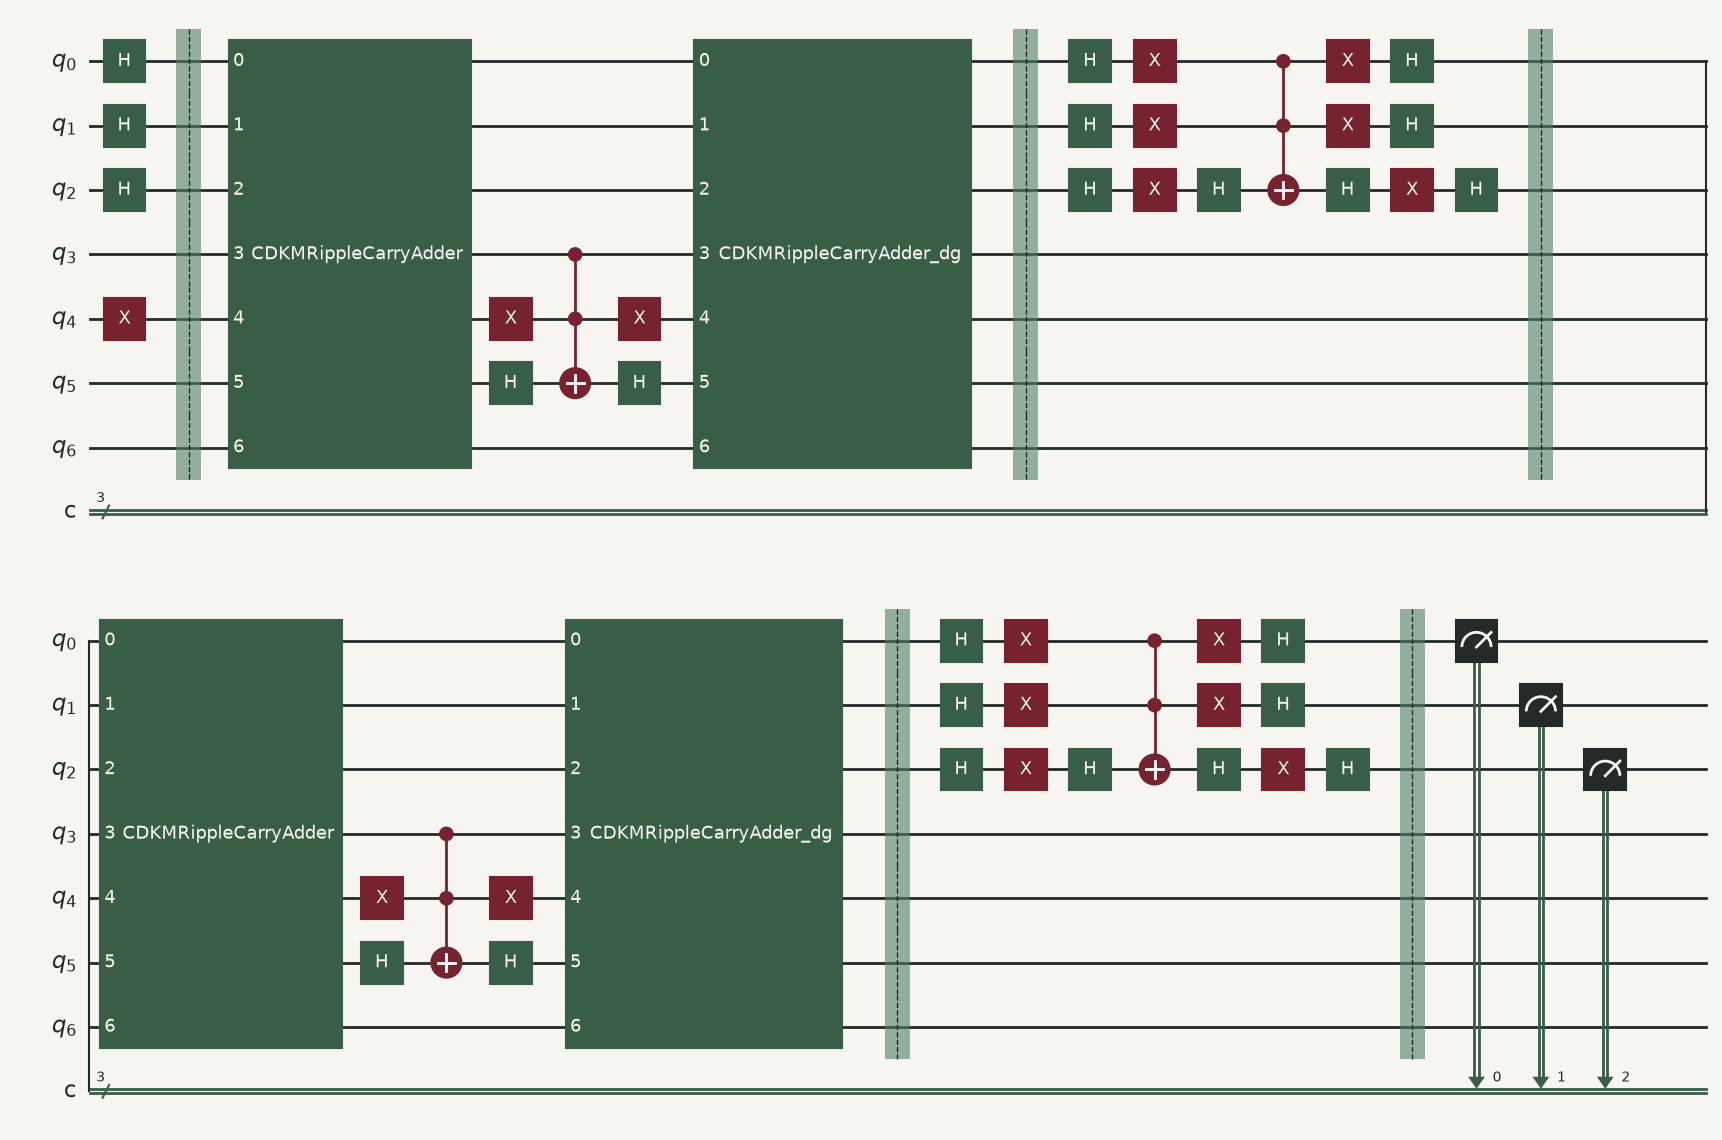

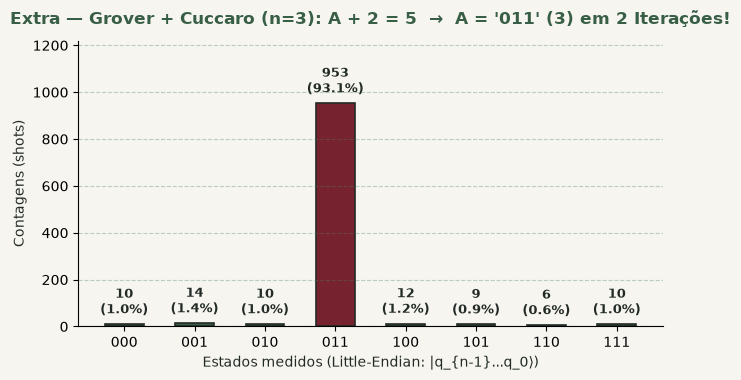

In [23]:
somador3 = CDKMRippleCarryAdder(3, kind="fixed")
qc_cuc3 = QuantumCircuit(7, 3)  # q0..q2 = A | q3..q5 = Y | q6 = aux

# 1. Inicializa Y = 2 ('010' -> porta X em q4) e coloca A (q0, q1, q2) em superposição
qc_cuc3.x(4)
qc_cuc3.h([0, 1, 2])
qc_cuc3.barrier()

# Fazemos 2 iterações de Grover (ótimo para N = 8 estados)
for passo in range(2):
    # --- ORÁCULO COM SOMADOR DE CUCCARO (n=3) ---
    qc_cuc3.append(somador3, [0, 1, 2, 3, 4, 5, 6])

    # Marca X = 5 ('101' em q5,q4,q3 -> bit '0' em q4 é envolvido por X antes e depois da CCZ)
    qc_cuc3.x(4)
    qc_cuc3.h(5)
    qc_cuc3.ccx(3, 4, 5)
    qc_cuc3.h(5)
    qc_cuc3.x(4)

    # Descomputa a soma para desemaranhar B de A
    qc_cuc3.append(somador3.inverse(), [0, 1, 2, 3, 4, 5, 6])
    qc_cuc3.barrier()

    # --- DIFUSOR DE GROVER EM A (qubits 0, 1, 2) ---
    qc_cuc3.h([0, 1, 2])
    qc_cuc3.x([0, 1, 2])
    qc_cuc3.h(2)
    qc_cuc3.ccx(0, 1, 2)
    qc_cuc3.h(2)
    qc_cuc3.x([0, 1, 2])
    qc_cuc3.h([0, 1, 2])
    qc_cuc3.barrier()

# Mede o registrador A (qubits 0, 1 e 2)
qc_cuc3.measure([0, 1, 2], [0, 1, 2])

display(qc_cuc3.draw(output="mpl", style=ESTILO_CIRCUITO_SLIDE))
plotar_histograma(simular(qc_cuc3), "Extra — Grover + Cuccaro (n=3): A + 2 = 5  →  A = '011' (3) em 2 Iterações!", estados_destaque=["011"])